# How the callout bounding boxes were found

This notebook repeats, step by step, how the research located every annotation ("callout") on a NIST drawing, before any AI model was involved.

**Short version.** The boxes do not come from analysing the picture. A PDF is a list of drawing instructions, such as "fill this outline in blue" or "draw a line from here to there". We read those instructions directly with PyMuPDF and then do three things:

1. Keep only the pure-blue ones, because on these drawings only the annotations are pure blue.
2. Group the blue letter shapes that sit close together, so that one group is one annotation.
3. Add the nearby frame lines to each group, and merge groups that overlap.

The picture is used only at the very end, to cut out the crop that a vision model reads.

The last section shows a second way that works from the rendered image alone, which uses blue pixels instead of blue PDF shapes, so the two can be compared.

Run it from `experiments/drawing/` (see the README there). It needs `pymupdf`, `numpy`, `opencv-python-headless` and `matplotlib`.

In [1]:
from pathlib import Path
import collections, math
import numpy as np, cv2, pymupdf
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

DRAWINGS = Path("../..") / "data" / "drawings"
PDF = DRAWINGS / "nist_ctc_01_asme1_rd.pdf"   # change to try another drawing
PAGE = 0
plt.rcParams["figure.dpi"] = 110

def show(img, boxes=(), title="", color="red", labels=False, size=(12, 9)):
    """Show an RGB image with optional boxes given in pixel coordinates (x0, y0, x1, y1)."""
    fig, ax = plt.subplots(figsize=size)
    ax.imshow(img); ax.set_title(title); ax.axis("off")
    for k, (x0, y0, x1, y1) in enumerate(boxes):
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor=color, linewidth=1.2))
        if labels:
            ax.text(x0, y0 - 4, str(k), color=color, fontsize=8, weight="bold")
    plt.show()

## Step 1. Open the page and look at it

This is what a person, or a vision model, would see. The page is stored sideways in the PDF (`/Rotate 270`), so every position we read from the PDF has to be turned the same way before it lines up with the picture. `page.rotation_matrix` does that.

page 792 x 612 pt, rotation 270, image 1650 x 1275 px
words in the PDF text layer: 32
text layer: PMI Complex Test Case 1 | Includes Atomic Test Cases - 1, 2, 3, 4, 7, 8, 17, 21, 33, 48 | NIST PMI Test Models - 2012 | Test Model 1 | Rev D | nist_ctc_01_asme1_rd | 


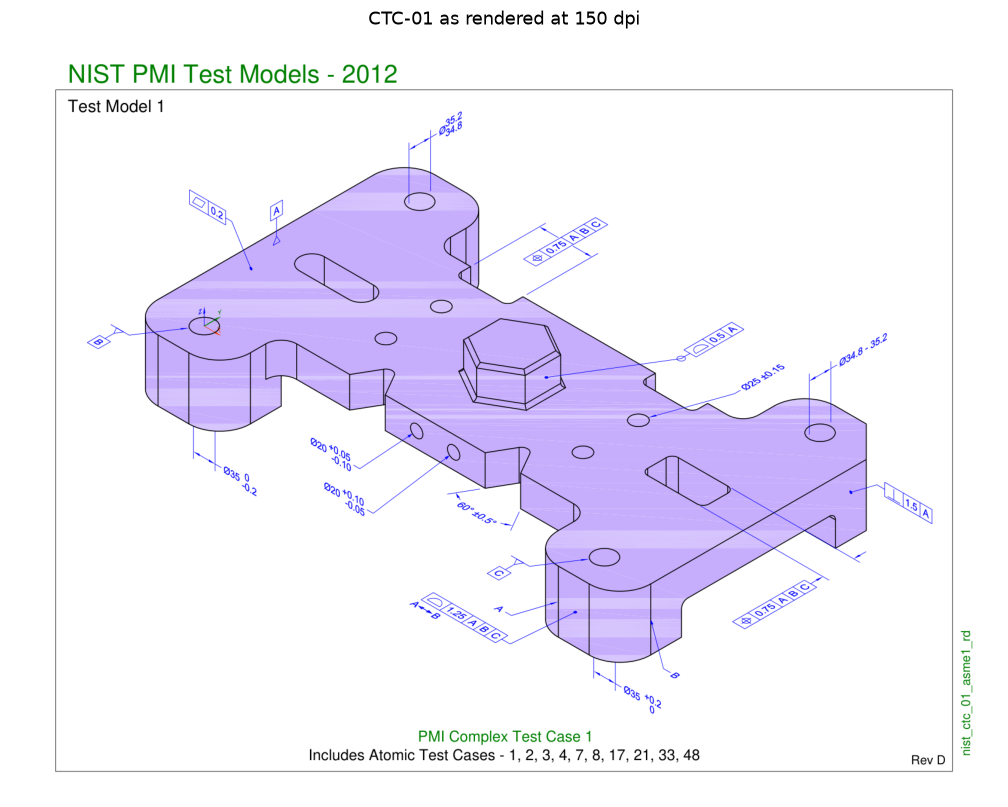

In [2]:
doc = pymupdf.open(PDF)
page = doc[PAGE]
DPI = 150
Z = DPI / 72                      # PDF units are points (1/72 inch); this converts points to pixels
ROT = page.rotation_matrix        # turns stored (unrotated) coordinates into displayed ones

pix = page.get_pixmap(dpi=DPI)
img = np.frombuffer(pix.samples, np.uint8).reshape(pix.h, pix.w, pix.n)[:, :, :3]
print(f"page {page.rect.width:.0f} x {page.rect.height:.0f} pt, rotation {page.rotation}, image {pix.w} x {pix.h} px")
print("words in the PDF text layer:", len(page.get_text("words")))
print("text layer:", page.get_text().replace(chr(10), " | "))
show(img, title="CTC-01 as rendered at 150 dpi")

The text layer holds only the title block. None of the dimensions, tolerances or datum letters are text: they are drawn as filled outlines. That is why we cannot simply copy them out of the PDF.

## Step 2. List every drawing instruction and count them by colour

`page.get_drawings()` returns one entry per path. Each entry has a type (`f` fill, `s` stroke, `fs` both), a colour, a line width and a bounding rectangle.

In [3]:
drawings = page.get_drawings()
def rgb(c):
    return None if c is None else tuple(round(x, 2) for x in c)

tally = collections.Counter((d["type"], rgb(d.get("color")) or rgb(d.get("fill"))) for d in drawings)
print(f"{len(drawings)} paths on this page")
for (kind, colour), n in tally.most_common(8):
    print(f"  {n:5d}  type={kind:2s}  colour={colour}")

1797 paths on this page
   1217  type=f   colour=(0.78, 0.69, 1.0)
    268  type=fs  colour=(0.0, 0.0, 1.0)
    167  type=s   colour=(0.0, 0.0, 1.0)
     92  type=s   colour=(0.0, 0.0, 0.0)
     44  type=f   colour=(0.0, 0.0, 1.0)
      3  type=fs  colour=(1.0, 0.25, 0.0)
      2  type=fs  colour=(0.0, 0.5, 0.0)
      1  type=f   colour=(0.0, 0.5, 0.0)


The colours tell the story:

- The large pastel group is the shaded faces of the part.
- Black `(0, 0, 0)` is the part outline.
- **Pure blue `(0, 0, 1)` is every annotation.** The filled-and-stroked (`fs`) blue paths are the letter shapes, the stroked (`s`) blue paths are lines (leaders, dimension lines, frame walls), and the filled (`f`) blue paths are arrowheads.

Across all 30 pages of the 11 drawings, pure blue is never used for anything else. That gives a free, exact filter.

## Step 3. Keep only the blue paths and split letters from lines

A letter shape is a blue `fs` path drawn with a very thin outline (0.06 pt). A line is a blue `s` path, 0.42 pt wide. We keep each letter's rectangle, and every straight line segment, both turned into displayed coordinates.

268 letter shapes, 353 line segments


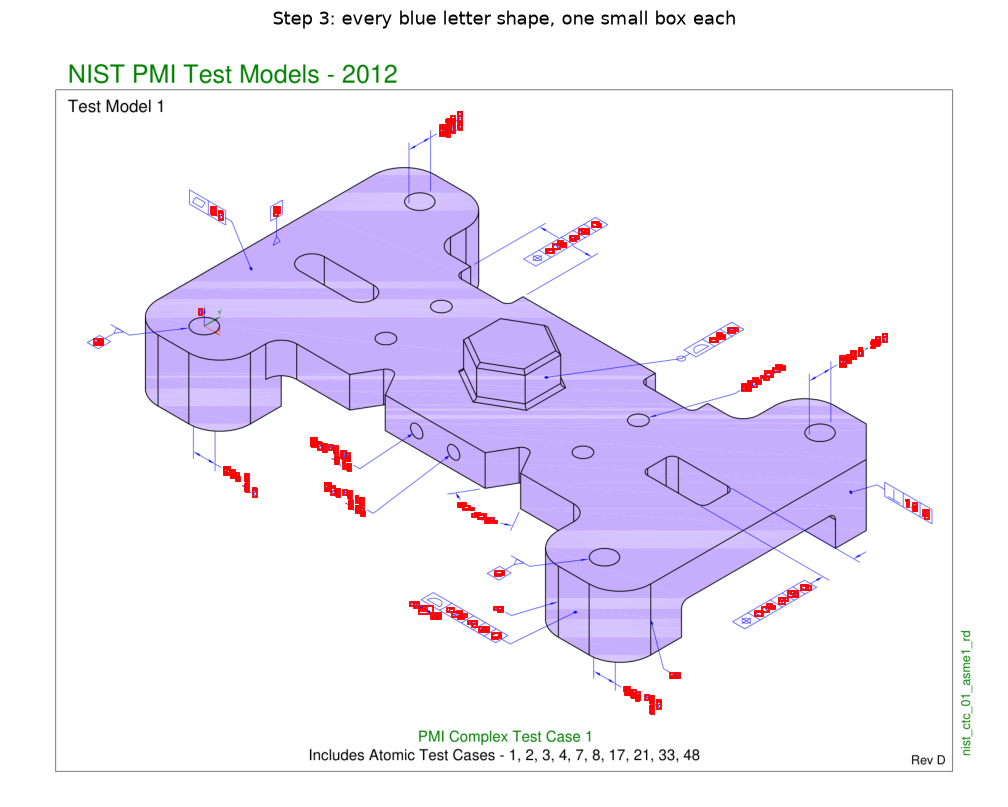

In [4]:
BLUE = (0.0, 0.0, 1.0)
is_blue = lambda c: rgb(c) == BLUE

glyphs, lines = [], []
for d in drawings:
    if not (is_blue(d.get("color")) or is_blue(d.get("fill"))):
        continue
    if d["type"] == "fs" and (d.get("width") or 0) < 0.1:
        glyphs.append(d["rect"] * ROT)                         # one letter or digit outline
    elif d["type"] == "s":
        for item in d["items"]:
            if item[0] == "l":                                 # straight line segment
                lines.append((item[1] * ROT, item[2] * ROT))
print(len(glyphs), "letter shapes,", len(lines), "line segments")

to_px = lambda r: (r.x0 * Z, r.y0 * Z, r.x1 * Z, r.y1 * Z)
show(img, [to_px(r) for r in glyphs], title="Step 3: every blue letter shape, one small box each")

Every small red box is one letter or digit. They are already in the right places, with no image analysis. What is missing is knowing which letters belong together.

## Step 4. Group letters that sit close together

Letters in the same annotation are close; different annotations are far apart. We use the typical letter size (`gh`, the median of each letter box's shorter side) as the yardstick, and join any two letters that are within 2 letter sizes of each other. A union-find structure keeps track of the groups.

typical letter size: 2.35 pt
23 letter groups


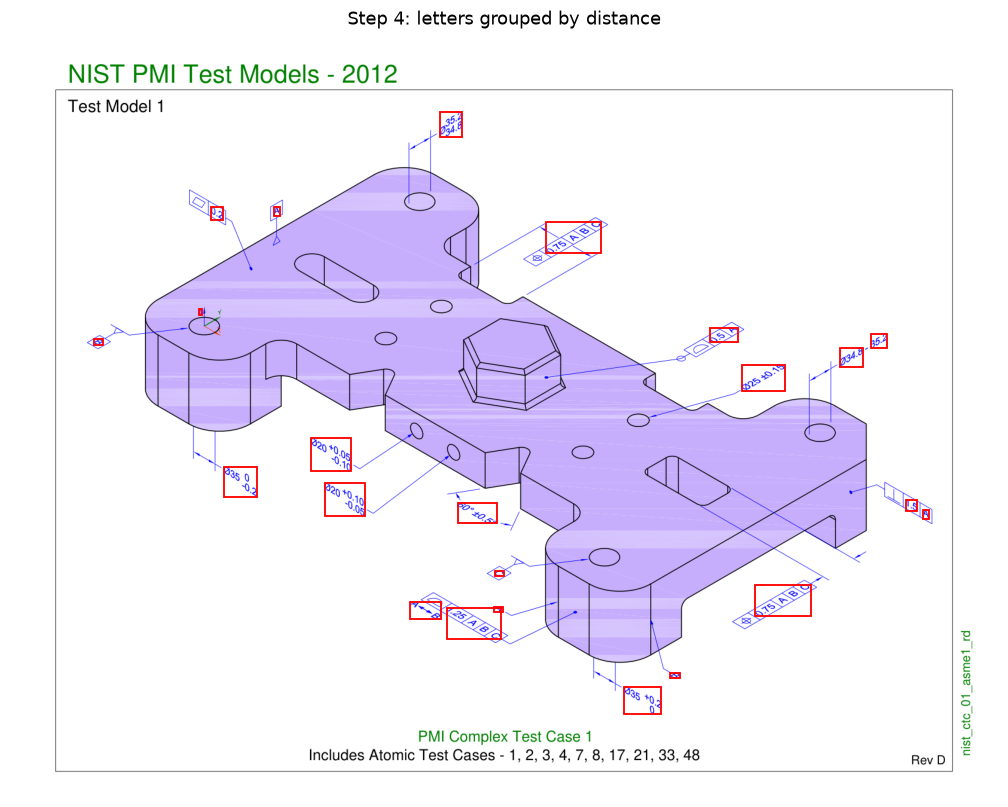

In [5]:
gh = float(np.median([max(min(r.width, r.height), 1) for r in glyphs]))
print(f"typical letter size: {gh:.2f} pt")

parent = list(range(len(glyphs)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i

pad = 2.0 * gh
grown = [pymupdf.Rect(r.x0 - pad, r.y0 - pad, r.x1 + pad, r.y1 + pad) for r in glyphs]
for i in range(len(glyphs)):
    for j in range(i + 1, len(glyphs)):
        if grown[i].intersects(glyphs[j]):
            parent[find(i)] = find(j)

groups = collections.defaultdict(list)
for i in range(len(glyphs)):
    groups[find(i)].append(i)

def text_angle(members):
    """Direction the text runs in, in degrees, from a straight-line fit through the letter centres."""
    if len(members) < 3:
        return 0.0
    c = np.array([((glyphs[i].x0 + glyphs[i].x1) / 2, (glyphs[i].y0 + glyphs[i].y1) / 2) for i in members])
    _, _, vt = np.linalg.svd(c - c.mean(0), full_matrices=False)
    return (math.degrees(math.atan2(vt[0][1], vt[0][0])) + 90) % 180 - 90

group_boxes, group_angles = [], []
for members in groups.values():
    box = pymupdf.Rect(glyphs[members[0]])
    for i in members[1:]:
        box |= glyphs[i]
    group_boxes.append(box)
    group_angles.append(text_angle(members))
print(len(group_boxes), "letter groups")
show(img, [to_px(b) for b in group_boxes], title="Step 4: letters grouped by distance")

Each group now covers the text of one annotation, for example `Ø20 +0.05 -0.10`. But a tolerance frame (the row of little boxes) is not fully covered: its first cell holds a symbol drawn with thin lines, not filled letters, and the cell walls are lines too.

## Step 5. Add the frame lines, then merge overlapping groups

For each group we add any blue line segment whose **two** end points both fall within 2.5 letter sizes of the group. Frame walls pass this test. Long leader lines do not, because one end is far away on the part.

Adding the walls can make two groups overlap, for example the tolerance cell and the datum cells of one frame. Groups that overlap, or nearly touch, are merged, but only when their text runs in roughly the same direction (within 20 degrees). That keeps apart two neighbouring annotations that lie on different faces of the 3D view.

22 callout boxes


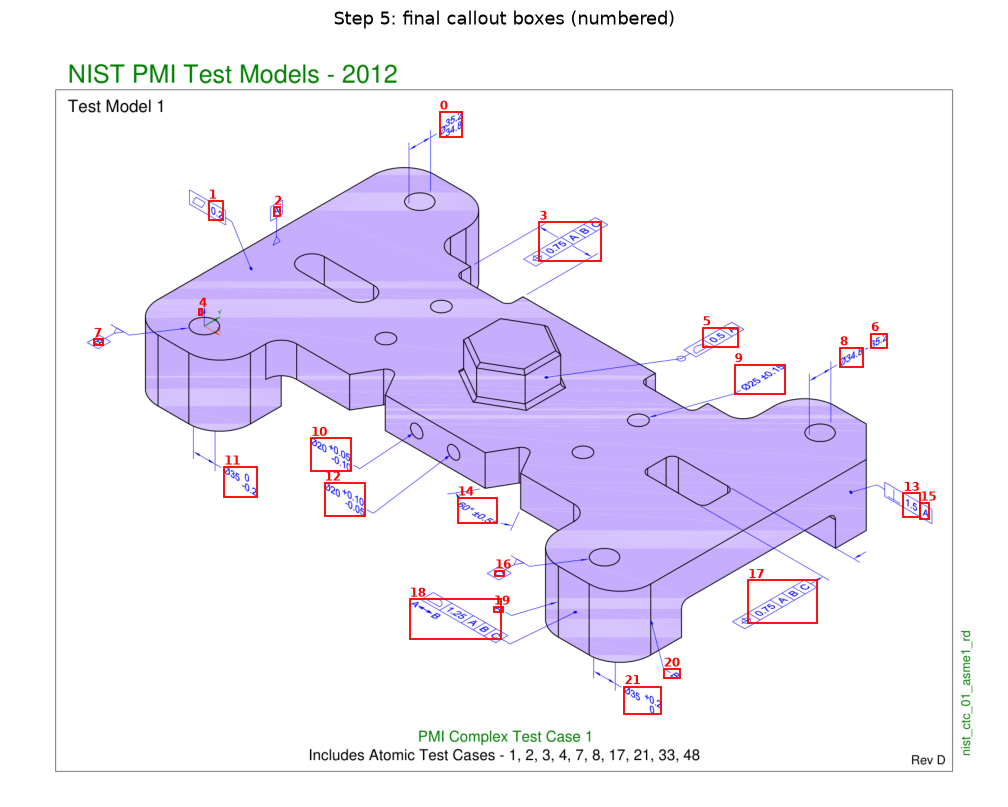

In [6]:
boxes, angles = [], list(group_angles)
for box in group_boxes:
    near = pymupdf.Rect(box.x0 - 2.5 * gh, box.y0 - 2.5 * gh, box.x1 + 2.5 * gh, box.y1 + 2.5 * gh)
    for a, b in lines:
        if near.contains(a) and near.contains(b):
            box = box | a | b
    boxes.append(box)

merged = True
while merged:
    merged = False
    for i in range(len(boxes)):
        for j in range(i + 1, len(boxes)):
            same_direction = abs(angles[i] - angles[j]) < 20
            if same_direction and (boxes[i] + (-gh, -gh, gh, gh)).intersects(boxes[j]):
                boxes[i] = boxes[i] | boxes[j]
                del boxes[j], angles[j]
                merged = True
                break
        if merged:
            break

boxes.sort(key=lambda b: (b.y0, b.x0))
print(len(boxes), "callout boxes")
show(img, [to_px(b) for b in boxes], title="Step 5: final callout boxes (numbered)", labels=True)

These are the boxes the research used: 22 on this page. Things to notice, which the research lists as known gaps:

- On some frames the box stops short of the first cell, so the symbol on the far left can be clipped.
- The small `Z` and other axis letters next to the coordinate arrows become tiny boxes. They are not annotations and need to be filtered out.
- On crowded drawings such as FTC-06, two annotations that sit close together can merge into one box. Set `PDF` to `nist_ftc_06_asme1_rd.pdf` in the first cell to see it.

## Step 6. Cut the crops a model reads

Only now is the picture used. Each box is turned from points into pixels on a 300 dpi render, and cut out with a generous margin (22 pt sideways, 16 pt up and down, about 8 mm by 6 mm). The margin is there because a tight box cut off frame symbols, and the model then misread them or skipped the frame.

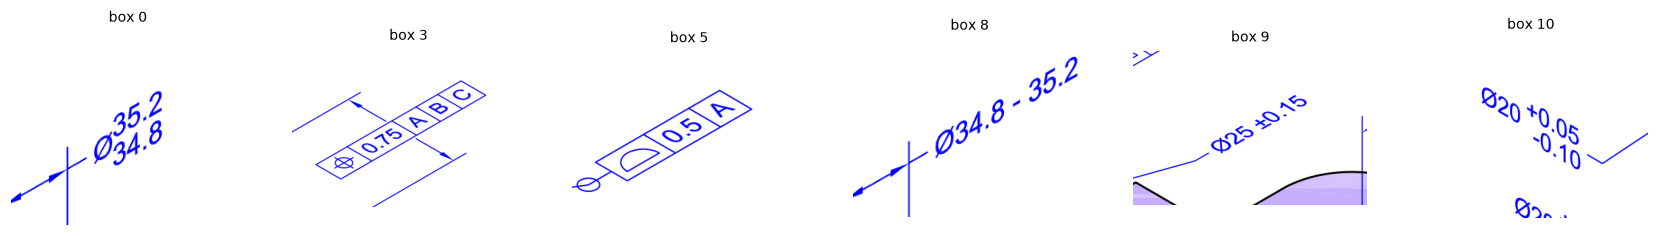

In [7]:
CROP_DPI = 300
big = page.get_pixmap(dpi=CROP_DPI)
big_img = np.frombuffer(big.samples, np.uint8).reshape(big.h, big.w, big.n)[:, :, :3]

def crop(box, dx=22, dy=16):
    r = (box + (-dx, -dy, dx, dy)) & page.rect
    k = CROP_DPI / 72
    return big_img[int(r.y0 * k):int(r.y1 * k), int(r.x0 * k):int(r.x1 * k)]

frames = [b for b in boxes if b.width > 6 * gh][:6]     # show a few of the larger callouts
fig, axes = plt.subplots(1, len(frames), figsize=(3.2 * len(frames), 3.2))
for ax, b in zip(np.atleast_1d(axes), frames):
    ax.imshow(crop(b)); ax.axis("off"); ax.set_title(f"box {boxes.index(b)}", fontsize=9)
plt.show()

Those crops are what went to Qwen3-VL in the tests.

## Optional: the same idea from the picture alone

If a drawing were a scanned image, there would be no PDF instructions to read. The same colour trick still works on pixels:

1. Mark every pixel that is clearly blue, meaning its blue channel is well above its red and green.
2. Thicken the marks a little so letters in one annotation touch each other (`cv2.dilate`).
3. Take each connected blob of marked pixels as one candidate box (`cv2.connectedComponentsWithStats`).

This version is shown for comparison only. It is noisier than the PDF route, because leaders and dimension lines are blue too: they join callouts to each other and to the part, so some blobs come out very large. The PDF route avoids this because it can tell letters from lines by their type and width.

23 blobs, 23 kept after dropping specks


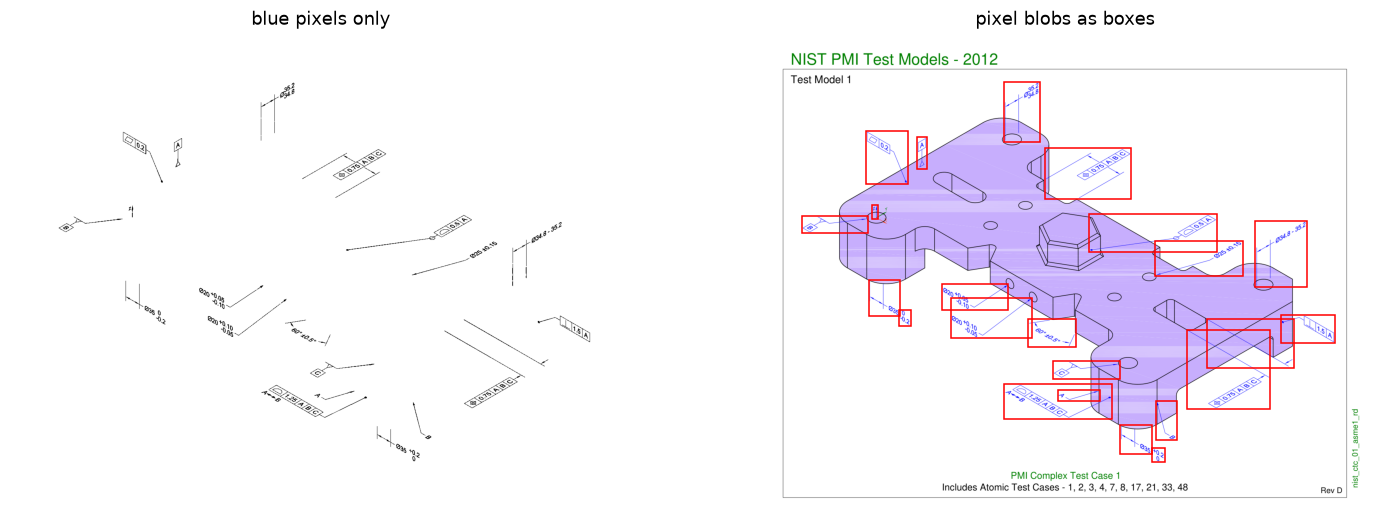

In [8]:
px = img.astype(int)
blueness = px[:, :, 2] - np.maximum(px[:, :, 0], px[:, :, 1])
mask = (blueness > 90).astype(np.uint8)

kernel = np.ones((7, 7), np.uint8)                    # about 1 mm at 150 dpi
joined = cv2.dilate(mask, kernel)
n, labels, stats, _ = cv2.connectedComponentsWithStats(joined)
pix_boxes = [(x, y, x + w, y + h) for x, y, w, h, area in stats[1:] if area > 40]
print(n - 1, "blobs,", len(pix_boxes), "kept after dropping specks")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
axes[0].imshow(mask, cmap="gray_r"); axes[0].set_title("blue pixels only"); axes[0].axis("off")
axes[1].imshow(img); axes[1].set_title("pixel blobs as boxes"); axes[1].axis("off")
for x0, y0, x1, y1 in pix_boxes:
    axes[1].add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, edgecolor="red", linewidth=1))
plt.show()

The left panel shows that the blue filter alone already isolates the annotations from the part. The right panel shows why the research used the PDF instructions instead: the leaders tie blobs together, so the boxes are less precise than the ones from Step 5.

## Where this sits in the plan

This locator is step 1 of Proposal 1 in `research/drawing/README.md`. Its planned improvement is to find each frame as a closed set of blue lines first and group the text on top of it, so frames are never split and neighbours are never merged.